# 01 — Εξερεύνηση του dataset `glossAPI/amna-press`

Βήμα 1 της εκφώνησης: κατηγορίες, ημερομηνίες, τίτλοι.

Προϋπόθεση: `python scripts/prepare_data.py` (δημιουργεί το `data/articles.parquet`).

In [1]:
import sys
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.normalize import normalize

RAW = (ROOT / 'data/Huggingface data source/amna-press.parquet').as_posix()
DATA = (ROOT / 'data/articles.parquet').as_posix()
con = duckdb.connect()
con.sql(f"CREATE VIEW raw AS SELECT * FROM read_parquet('{RAW}')")
con.sql(f"CREATE VIEW a AS SELECT * FROM read_parquet('{DATA}')")

## 1. Στήλες και τύποι (αρχικό αρχείο)

In [2]:
con.sql('DESCRIBE raw').df()

,column_name,column_type,null,key,default,extra
0,id,VARCHAR,YES,None,None,None
1,category,VARCHAR,YES,None,None,None
2,title,VARCHAR,YES,None,None,None
3,abstract,VARCHAR,YES,None,None,None
4,text_clean,VARCHAR,YES,None,None,None
5,author,VARCHAR,YES,None,None,None
6,created,TIMESTAMP_NS,YES,None,None,None
7,modified,TIMESTAMP_NS,YES,None,None,None
8,tags,VARCHAR,YES,None,None,None
9,url,VARCHAR,YES,None,None,None


In [3]:
con.sql('SELECT count(*) AS raw_rows FROM raw').df().join(con.sql('SELECT count(*) AS clean_rows FROM a').df())

,raw_rows,clean_rows
0,341762,341613


## 2. Κενές τιμές ανά στήλη

In [4]:
cols = ['category','title','abstract','text_clean','author','tags','url']
q = ', '.join(f"avg((coalesce(trim({c}),'') = '')::INT) AS {c}" for c in cols)
con.sql(f'SELECT {q} FROM raw').df().T.rename(columns={0: 'ποσοστό κενών'}).style.format('{:.1%}')

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,ποσοστό κενών
category,0.0%
title,0.0%
abstract,70.1%
text_clean,0.0%
author,84.9%
tags,90.4%
url,0.0%


## 3. Κατηγορίες

In [5]:
cats = con.sql('SELECT category, count(*) AS n FROM a GROUP BY 1 ORDER BY n DESC').df()
cats

,category,n
0,Πολιτική,99988
1,Κόσμος,99923
2,Ελλάδα,74861
3,Οικονομία,41011
4,Πολιτισμός,17619
5,Επιστήμη,8211


## 4. Ημερομηνίες — εύρος και όγκος ανά μήνα

Σημαντικό για την εφαρμογή: αν ο συνολικός όγκος αλλάζει πολύ, οι κορυφές πρέπει να υπολογίζονται σε **ποσοστό** άρθρων του μήνα και όχι σε απόλυτο πλήθος.

In [6]:
con.sql('SELECT min(created) AS first, max(created) AS last FROM a').df()

,first,last
0,2011-06-29 10:29:10,2026-03-30 20:39:16


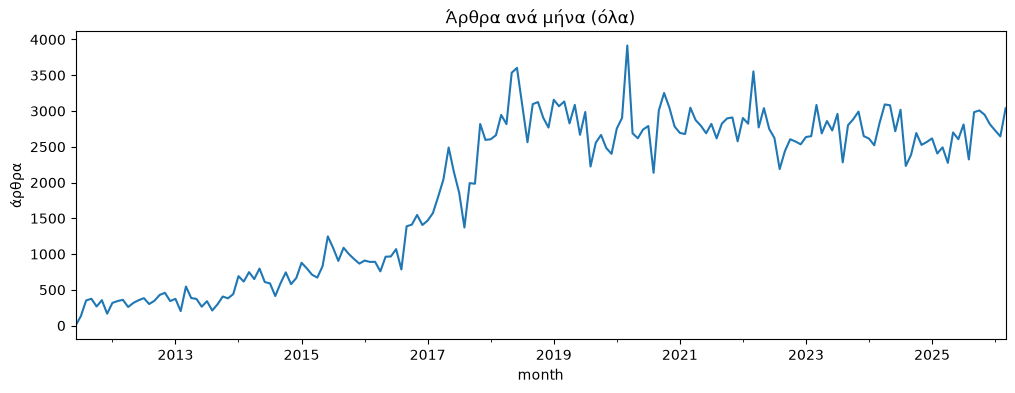

In [7]:
monthly = con.sql('SELECT month, count(*) AS n FROM a GROUP BY 1 ORDER BY 1').df()
ax = monthly.plot(x='month', y='n', figsize=(12, 4), legend=False, title='Άρθρα ανά μήνα (όλα)')
ax.set_ylabel('άρθρα');

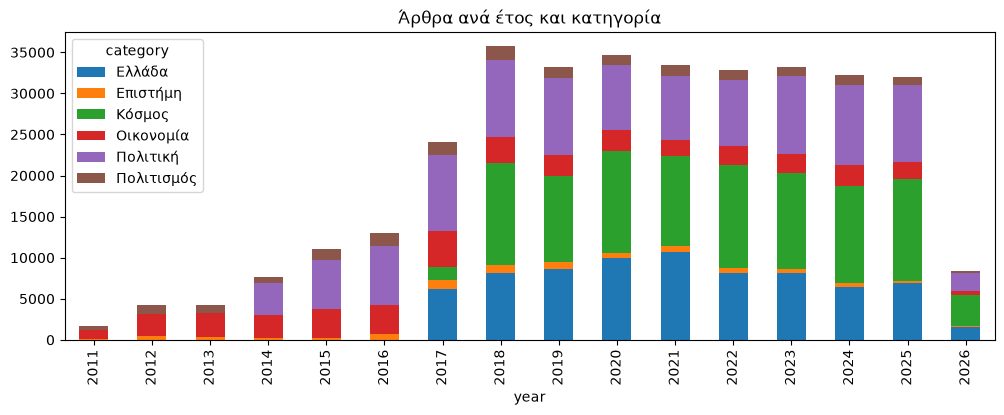

In [8]:
by_cat = con.sql('SELECT year(month) AS year, category, count(*) AS n FROM a GROUP BY ALL').df()
by_cat.pivot(index='year', columns='category', values='n').plot.bar(stacked=True, figsize=(12, 4), title='Άρθρα ανά έτος και κατηγορία');

In [9]:
# Μήνες με ασυνήθιστα λίγα άρθρα (πιθανά κενά στη συλλογή)
monthly.nsmallest(10, 'n')

,month,n
0,2011-06-01,1
1,2011-07-01,132
6,2011-12-01,166
20,2013-02-01,202
26,2013-08-01,211
10,2012-04-01,260
24,2013-06-01,264
4,2011-10-01,267
27,2013-09-01,296
14,2012-08-01,301


## 5. Τίτλοι

In [10]:
con.sql('SELECT created, category, title FROM a USING SAMPLE 15 ROWS').df()

,created,category,title
0,2013-03-08 10:48:57,Οικονομία,"Ο Αναστασιάδης έχει ""plan B"" αν καθυστερήσει η..."
1,2015-01-05 11:15:58,Πολιτική,Γ. Πεταλωτής: Αναγνωρίζοντας τα λάθη και τις π...
2,2015-03-22 13:15:54,Πολιτική,Ντ. Μπακογιάννη: Είναι η ώρα να υπάρξει μια εθ...
3,2015-05-18 20:04:34,Οικονομία,«Δεν υπάρχει τέτοιο κείμενο από την Κομισιόν»
4,2019-08-13 22:31:19,Ελλάδα,Αντιπυρική ζώνη στα Ψαχνά Ευβοίας - Συνεχίζετα...
5,2019-09-23 07:53:37,Πολιτική,Την ελληνική πρόταση για προστασία της πολιτισ...
6,2020-01-07 08:29:25,Επιστήμη,Μεγαλύτερος ο κίνδυνος εγκεφαλικού για όσους σ...
7,2020-02-28 11:39:51,Πολιτική,Ο πρωθυπουργός για τον θάνατο της Άλκης Ζέη
8,2023-05-16 19:01:10,Πολιτική,Γκ. Χαρδούβελης: Η επόμενη μέρα για το τραπεζι...
9,2023-07-06 12:56:23,Κόσμος,Μ. Σχοινάς: Η Ευρώπη γυρίζει σελίδα στη μετανά...


In [11]:
con.sql('''SELECT quantile_cont(length(title), [0.05, 0.5, 0.95]) AS title_len_q,
                  quantile_cont(length(text_norm), [0.05, 0.5, 0.95]) AS text_len_q FROM a''').df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,title_len_q,text_len_q
0,"[44.0, 79.0, 128.0]","[548.0, 1847.0, 6995.0]"


In [12]:
# Διπλότυποι τίτλοι (π.χ. επαναλαμβανόμενα δελτία)
con.sql('SELECT title, count(*) AS n FROM a GROUP BY 1 HAVING n > 5 ORDER BY n DESC LIMIT 15').df()

,title,n
0,Αποκαταστάθηκε η κυκλοφορία των οχημάτων στο κ...,11
1,Συνεδριάζει η Πολιτική Γραμματεία του ΣΥΡΙΖΑ,10
2,Πυρκαγιά σε χαμηλή βλάστηση στον Ασπρόπυργο,10
3,"Σημεία δωρεάν ελέγχου Covid-19 από τον ΕΟΔΥ, σ...",10
4,Συνεδριάζει το υπουργικό συμβούλιο,9
5,Υπό μερικό έλεγχο η πυρκαγιά σε χαμηλή βλάστησ...,9
6,Σε εξέλιξη η συνάντηση Αντ. Σαμαρά - Ευ. Βενιζ...,8
7,Προβάδισμα του ΣΥΡΙΖΑ σε νέα δημοσκόπηση,8
8,Συνάντηση Αντ. Σαμαρά - Ευ. Βενιζέλου,7
9,Συνεδριάζει αύριο το υπουργικό συμβούλιο,7


## 6. Πρώτη δοκιμή: άρθρα ανά μήνα για έναν όρο

Αναζήτηση με **πρόθεμα** στο κανονικοποιημένο κείμενο, ώστε να πιάνονται κλιτικοί τύποι («μνημόνιο», «μνημονίου», «μνημόνια» → `μνημον`). Συγκρίνουμε τίτλους μόνο vs τίτλο + κείμενο.

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

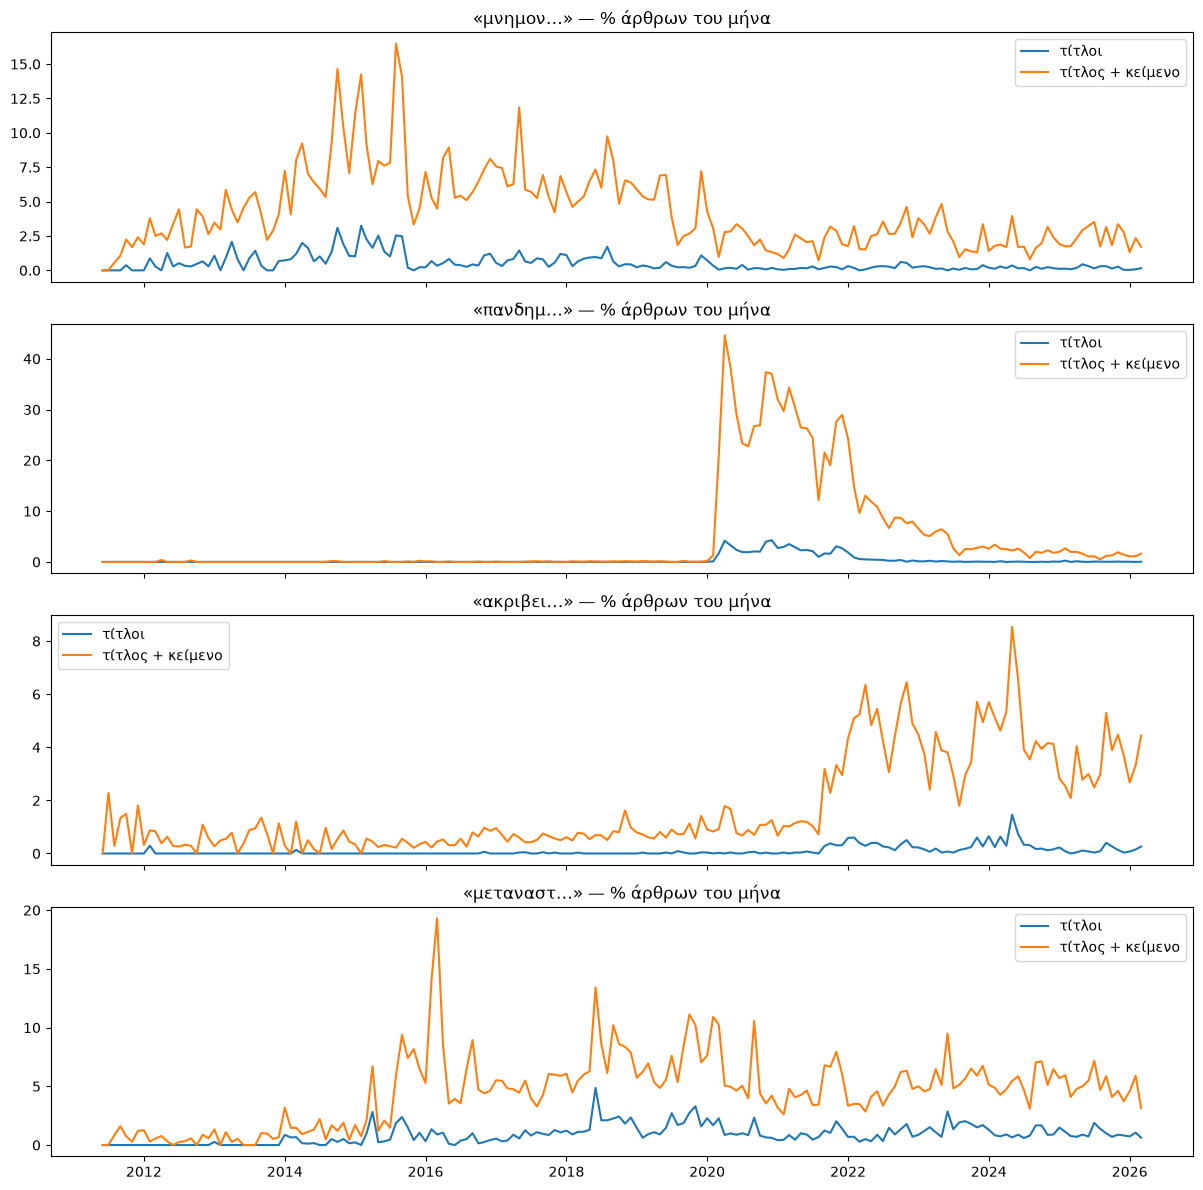

In [13]:
def term_monthly(stem: str, field: str = 'title_norm') -> pd.DataFrame:
    # Αρχή λέξης: το \b του RE2 είναι μόνο ASCII, οπότε χρησιμοποιούμε κλάση γραμμάτων Unicode
    pattern = r'(^|[^\p{L}])' + normalize(stem)
    return con.sql(f'''
        SELECT month, count(*) AS total,
               sum(regexp_matches({field}, $p)::INT) AS hits
        FROM a GROUP BY 1 ORDER BY 1''', params={'p': pattern}).df().assign(share=lambda d: d.hits / d.total)

terms = ['μνημον', 'πανδημ', 'ακριβει', 'μεταναστ']
fig, axes = plt.subplots(len(terms), 1, figsize=(12, 3 * len(terms)), sharex=True)
for ax, t in zip(axes, terms):
    for field, label in [('title_norm', 'τίτλοι'), ('text_norm', 'τίτλος + κείμενο')]:
        d = term_monthly(t, field)
        ax.plot(d.month, d.share * 100, label=label)
    ax.set_title(f'«{t}…» — % άρθρων του μήνα'); ax.legend()
plt.tight_layout()

In [14]:
# Οι 5 μήνες με το υψηλότερο ποσοστό για «μνημον» (τίτλοι)
term_monthly('μνημον').nlargest(5, 'share')

,month,total,hits,share
44,2015-02-01,800,26.0,0.032500
40,2014-10-01,744,23.0,0.030914
50,2015-08-01,904,23.0,0.025442
47,2015-05-01,830,21.0,0.025301
51,2015-09-01,1088,27.0,0.024816


## 7. Παρατηρήσεις (εκτέλεση 20/10/2026)

- **Μέγεθος:** 341.762 άρθρα → 341.613 μετά τον καθαρισμό (αφαιρέθηκαν 149: άρθρα-δοκιμές, κενά κείμενα, διπλότυπα id).
- **Εύρος:** 29/06/2011 – 30/03/2026. Ο Ιούνιος 2011 έχει μόνο 1 άρθρο → εξαιρείται ως ημιτελής μήνας.
- **Όγκος ανά μήνα:** αυξάνεται ~10 φορές — ~300/μήνα το 2011–13, ~1.000 το 2015, ~2.500–3.500 μετά το 2018.
  Άρα το απόλυτο πλήθος άρθρων ευνοεί τα πρόσφατα έτη· οι κορυφές πρέπει να υπολογίζονται σε **ποσοστό** του μήνα.
  Στα πρώτα έτη ο παρονομαστής είναι μικρός → το ποσοστό έχει περισσότερο «θόρυβο».
- **Κατηγορίες:** 6 — Πολιτική (99.988), Κόσμος (99.923), Ελλάδα (74.861), Οικονομία (41.011), Πολιτισμός (17.619), Επιστήμη (8.211).
- **Κενά πεδία:** το `abstract` είναι κενό στο ~70%, άρα δεν αρκεί για αναζήτηση· χρειάζεται τίτλος + κείμενο.
- **Μήκος:** τίτλος ~79 χαρακτήρες (διάμεσος), κείμενο ~1.850 χαρακτήρες (διάμεσος).
- **Διπλότυποι τίτλοι:** λίγοι (≤ 11 επαναλήψεις, π.χ. τακτικά δελτία κυκλοφορίας/πυρκαγιών) — δεν επηρεάζουν ουσιαστικά.
- **Τίτλοι vs κείμενο:** η αναζήτηση μόνο στους τίτλους δίνει αραιό σήμα (συνήθως < 3%). Η αναζήτηση σε τίτλο + κείμενο δίνει
  καθαρές κορυφές που αντιστοιχούν σε πραγματικά γεγονότα:
  - «πανδημ…»: σχεδόν 0 πριν το 2020 → ~45% των άρθρων τον Μάρτιο 2020, και δεύτερο κύμα στα τέλη του 2020.
  - «μνημον…»: κορυφές 2014–2015, μέγιστο ~16,5% το καλοκαίρι του 2015 (δημοψήφισμα / 3ο μνημόνιο).
  - «ακριβει…»: άνοδος από τα τέλη του 2021, κορυφές 2022 και 2024 (κύμα πληθωρισμού).
  - «μεταναστ…»: κορυφή αρχές 2016 (προσφυγική κρίση).
- **Αποφάσεις για τη Φάση 2:**
  1. Ανίχνευση κορυφών στο **ποσοστό** άρθρων του μήνα, με αναζήτηση σε **τίτλο + κείμενο** (προεπιλογή).
  2. Οι **τίτλοι** των άρθρων της κορυφής τροφοδοτούν τη σύνοψη του LLM.
  3. Εξαίρεση ημιτελών μηνών (Ιούνιος 2011).
  4. Το αρχείο `articles.parquet` είναι 421 MB — για τη δημοσίευση θα χρειαστεί πιο ελαφριά μορφή (Φάση 6).
